# Machine Learning Midterm – Wine Classification
**Muhammed Efe Öneş – 23040202015**

Same steps as breast_cancer.ipynb. Differences: 3 classes, one-vs-rest ROC-AUC, K-Means with 3 clusters.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn



In [2]:
#PART 1 loading Data set
#1.1 loading data set from sicit-learn
from sklearn.datasets import load_wine
data= load_wine()
print(type(data))
print(data.keys()) # different parts of the data set

<class 'sklearn.utils._bunch.Bunch'>
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])


In [3]:
#1.2 Creating the data frames
X = pd.DataFrame(data.data, columns=data.feature_names) # to give names for the columns in data (easy to read)
y = pd.Series(data.target, name="target") #like in x but only for target column (0, 1, 2)
print("X shape:", X.shape)
print("y shape:", y.shape) 
display(X.head()) #For first five 
y.head() 

X shape: (178, 13)
y shape: (178,)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [4]:
print("Feature names:", list(X.columns)) #names of the colum in data set 
print("Target labels:", np.unique(y)) #shows how different answer in the colummn 
print("Target names :", list(data.target_names))

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target labels: [0 1 2]
Target names : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


In [5]:
counts = y.value_counts().sort_index() #it count how many wines for every class (without sort_index values will be mixed)
class_overview = pd.DataFrame({
    "label": counts.index, #[0,1,2]
    "name": data.target_names, #[class_0, class_1, class_2] (3 grape types)
    "n_samples": counts.values, #[values of how many 0, 1 and 2 in counts]
})
class_overview["percent"] = (100 * class_overview["n_samples"] / len(y)).round(2) #percentage of every class in data set
class_overview

,label,name,n_samples,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


**Interpretation (Section 1):** 178 wines and 13 features (chemical measurements). Labels 0, 1, 2 are three grape types (class_0, class_1, class_2), there is no positive class. Classes are a bit imbalanced (59 / 71 / 48), so we use stratify and macro scores later.

In [6]:
# 2. Dataset Quality Checks
#2.1 Missing values and duplicates

In [7]:
missing = X.isna().sum() #to find missing values and sum them up 
display(missing.to_frame("missing_count"))  
print("Total missing values:", missing.sum())

n_duplicates = X.duplicated().sum() #to find işs there any dublicatre rows for protecting ml from leacge
print("Duplicate rows:", n_duplicates)

if missing.sum() == 0:
    print("No missing values are present.")
if n_duplicates == 0:
    print("No duplicate rows are present.")

,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Total missing values: 0
Duplicate rows: 0
No missing values are present.
No duplicate rows are present.


In [8]:
# 2.2 Potential outliers
outlier_rows = [] 
for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1 
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_iqr = ((X[col] < lower) | (X[col] > upper)).sum() #is the valur smaller than lower or bigger than upper? if yes, sum it up

    z = (X[col] - X[col].mean()) / X[col].std() #z score 
    n_z = (z.abs() > 3).sum()

    outlier_rows.append({
        "feature": col,
        "n_iqr_outliers": n_iqr,
        "pct_iqr": round(100 * n_iqr / len(X), 2),
        "n_abs_z_gt_3": n_z,
    })

outliers = pd.DataFrame(outlier_rows).sort_values("n_iqr_outliers", ascending=False) #puts bigest value to the top
print("Features with at least one IQR outlier:", (outliers["n_iqr_outliers"] > 0).sum(), "of", X.shape[1])
outliers
#7 of 13 features have some outliers, at most 4 each (magnesium, alcalinity of ash, color intensity). we find them to see how they can affect the models

Features with at least one IQR outlier: 7 of 13


,feature,n_iqr_outliers,pct_iqr,n_abs_z_gt_3
4,magnesium,4,2.25,2
3,alcalinity_of_ash,4,2.25,1
9,color_intensity,4,2.25,1
1,malic_acid,3,1.69,1
2,ash,3,1.69,3
8,proanthocyanins,2,1.12,1
10,hue,1,0.56,1
0,alcohol,0,0.00,0
5,total_phenols,0,0.00,0
7,nonflavanoid_phenols,0,0.00,0


In [9]:
# 2.3 Data types
display(X.dtypes.to_frame("dtype")) #it shows data type of all columns

n_numeric = X.select_dtypes(include="number").shape[1] # gives the nnumber of numeric columns in the data set
n_categorical = X.shape[1] - n_numeric
print("Numerical features  :", n_numeric)
print("Categorical features:", n_categorical)

zero_counts = (X == 0).sum() #how many zeros in each column
print("\nFeatures that contain exact zeros:")
print(zero_counts[zero_counts > 0])
#There are no missing values and no duplicate rows, so no imputation is needed. All 13 features are numerical and there are no exact zeros. Some features have outliers but they look like real values, so I did not change the data.

,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Numerical features  : 13
Categorical features: 0

Features that contain exact zeros:
Series([], dtype: int64)


In [10]:
# 3. Exploratory DAta analysis (EDA)
# 3.1 Descriptive statistics
desc = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
}).round(4)
desc
#if mean and median are close to each other, the distribution is symmetric. 

,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000


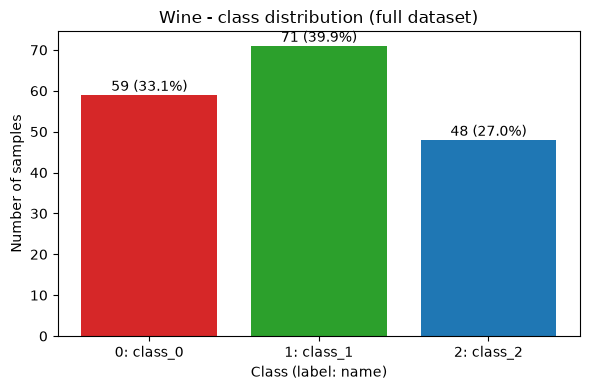

In [11]:
# 3.2 Class distribution and correlations
import os
os.makedirs("figures", exist_ok=True)

counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["0: class_0", "1: class_1", "2: class_2"], counts.values, color=["tab:red", "tab:green", "tab:blue"])
for i, c in enumerate(counts.values):
    ax.text(i, c + 1, f"{c} ({100 * c / len(y):.1f}%)", ha="center")
ax.set_xlabel("Class (label: name)")
ax.set_ylabel("Number of samples")
ax.set_title("Wine - class distribution (full dataset)")
plt.tight_layout()
plt.savefig("figures/wine_class_distribution.png", dpi=150)
plt.show()
#this part plots the graph of how many wines are in each class

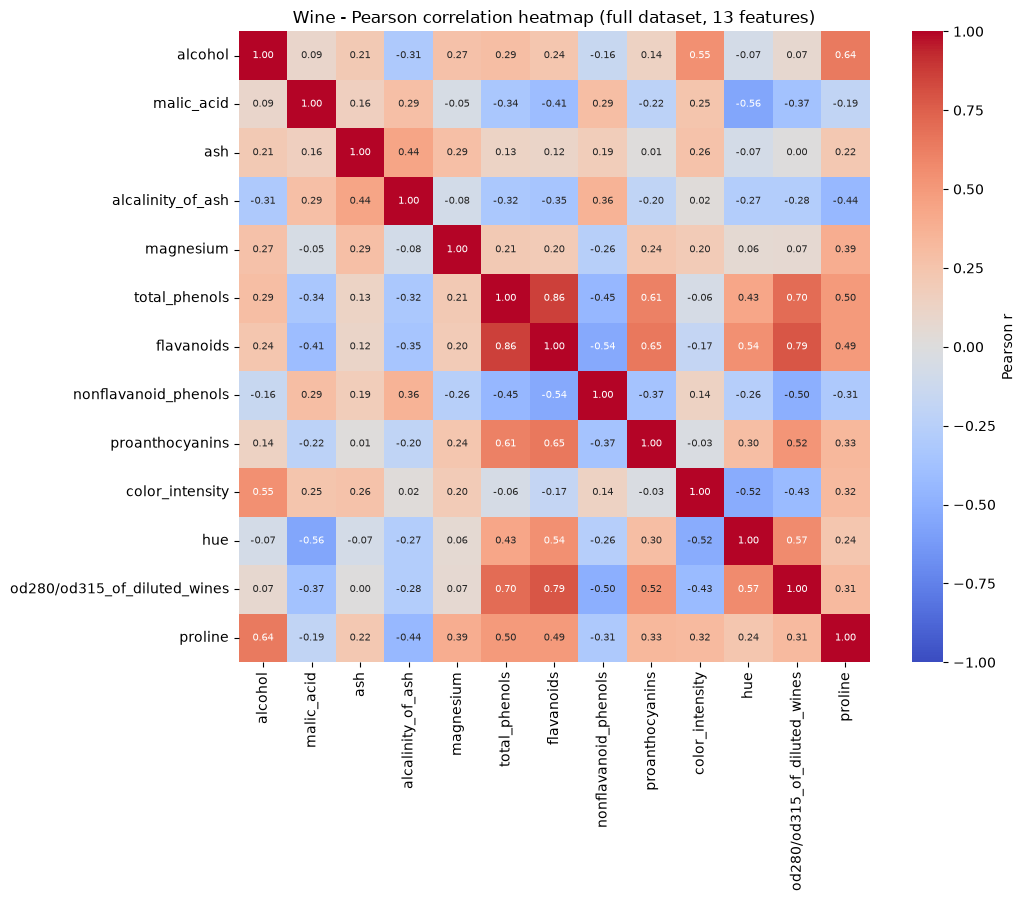

In [12]:
corr = X.corr(method="pearson") #13x13 bi tablo üretir

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax, #heat map (red positive, blue negative), annot writes the numbers inside
            annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "Pearson r"})
ax.set_title("Wine - Pearson correlation heatmap (full dataset, 13 features)")
plt.tight_layout()
plt.savefig("figures/wine_correlation_heatmap.png", dpi=150)
plt.show()

In [13]:
pairs = []
cols = corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):#j is starts from i+1 to avoid corners because every feature is  perfect korelasyon
        pairs.append((cols[i], cols[j], corr.iloc[i, j]))

pairs = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"])
pairs["abs_r"] = pairs["pearson_r"].abs()
top3 = pairs.sort_values("abs_r", ascending=False).head(3)
print("Number of unique pairs:", len(pairs))
top3

Number of unique pairs: 78


,feature_1,feature_2,pearson_r,abs_r
50,total_phenols,flavanoids,0.864564,0.864564
61,flavanoids,od280/od315_of_diluted_wines,0.787194,0.787194
55,total_phenols,od280/od315_of_diluted_wines,0.699949,0.699949


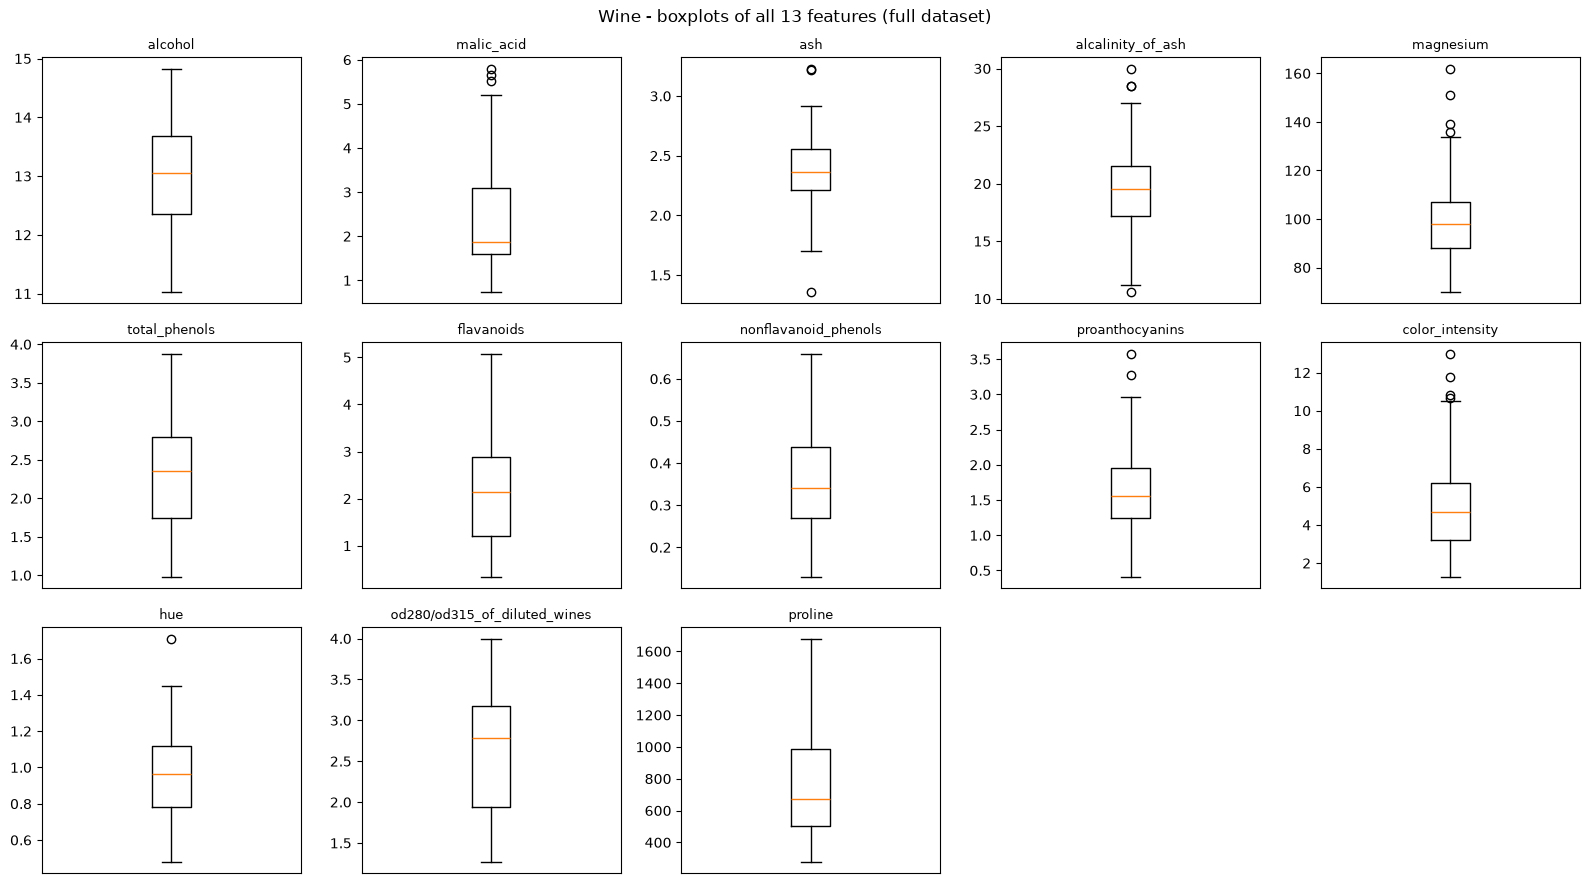

In [14]:
# 3.3 Boxplots
def plot_boxplots(features, title, filename): #[it's like a cast if you put wanted values it will give you same shape but with different materials]
    fig, axes = plt.subplots(3, 5, figsize=(16, 9)) # 13 features -> 3x5 grid, last 2 boxes empty
    for ax, col in zip(axes.ravel(), features):
        ax.boxplot(X[col])
        ax.set_title(col, fontsize=9)
        ax.set_xticks([])
    for ax in axes.ravel()[len(features):]:
        ax.axis("off") # hide empty boxes
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

plot_boxplots(list(X.columns), "Wine - boxplots of all 13 features (full dataset)", "figures/wine_boxplots.png")

**Interpretation (Section 3):** classes are a bit imbalanced, a model that always says class_1 gets 39.9 % accuracy, so we use macro-F1. Strongest pairs: total_phenols – flavanoids (0.865), flavanoids – od280/od315 (0.787), total_phenols – od280/od315 (0.700), they all measure phenols. Boxplots: feature sizes are very different (proline 278–1680, hue below 2), so KNN and K-Means need scaling. Only a few outliers. This part is only descriptive, nothing was removed.

In [15]:
# 4. Splitting the Dataset
# 4.1 Fix the test set and repeat the training/validation split
from sklearn.model_selection import train_test_split

SEEDS = [42, 52, 62]

# 20% test set, created ONCE
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

# for each seed: split the remaining 80% into train (70%) and validation (10%)
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed)
    splits[seed] = {"X_train": X_train, "X_val": X_val, "y_train": y_train, "y_val": y_val}

In [16]:
# 4.2 Verify the split
rows = []
for seed in SEEDS:
    for name, ys in [("train", splits[seed]["y_train"]),
                     ("validation", splits[seed]["y_val"]),
                     ("test", y_test)]:
        rows.append({"seed": seed, "subset": name, "n": len(ys),
                     "percent": round(100 * len(ys) / len(y), 2),
                     "class_0": (ys == 0).sum(),
                     "class_1": (ys == 1).sum(),
                     "class_2": (ys == 2).sum()})

split_summary = pd.DataFrame(rows)
split_summary
# this table shows how many wines go to train, validation and test for every seed, like a little report card for the split

,seed,subset,n,percent,class_0,class_1,class_2
0,42,train,124,69.66,41,50,33
1,42,validation,18,10.11,6,7,5
2,42,test,36,20.22,12,14,10
3,52,train,124,69.66,41,50,33
4,52,validation,18,10.11,6,7,5
5,52,test,36,20.22,12,14,10
6,62,train,124,69.66,41,50,33
7,62,validation,18,10.11,6,7,5
8,62,test,36,20.22,12,14,10


In [17]:
for seed in SEEDS:
    tr = splits[seed]["X_train"].index
    va = splits[seed]["X_val"].index
    te = X_test.index
    print(f"Seed {seed}: overlaps = {len(tr.intersection(va))}, {len(tr.intersection(te))}, {len(va.intersection(te))} | "
          f"total = {len(tr) + len(va) + len(te)} | first val rows = {sorted(va)[:5]}")

print("Test rows (same for all seeds), first 10:", sorted(X_test.index)[:10])
# here we check nobody is in two groups at same time, total is still 178 and test group is same in every seed


Seed 42: overlaps = 0, 0, 0 | total = 178 | first val rows = [0, 1, 4, 6, 33]
Seed 52: overlaps = 0, 0, 0 | total = 178 | first val rows = [2, 31, 33, 34, 40]
Seed 62: overlaps = 0, 0, 0 | total = 178 | first val rows = [2, 9, 15, 25, 27]
Test rows (same for all seeds), first 10: [7, 10, 14, 18, 20, 22, 28, 38, 42, 48]


**Interpretation (Section 4):** test set (36) is fixed for all seeds. Every seed gives 124 train and 18 validation wines with the same class ratio, no overlap, total 178. Seed 42 was chosen before for the final test.

In [18]:
# 5. Data Preprocessing and Scaling
# 5.1 Missing values
#There are no missing values (from Section 2.1), so no imputation step is needed.
# 5.2 Selected scaler
#use Standardscaler for all seeds and for both datasets.
# 5.3 Fit and apply the scaler

In [19]:
# every seed gets its own new ruler, made only from its own train data
from sklearn.preprocessing import StandardScaler

scalers = {} #box for keeping the ruler of every seed
scaled = {} # box for keeping scaled train and val of every seed
for seed in SEEDS: # do same thing 3 times: seed 42, 52, 62
    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(splits[seed]["X_train"])# ruler learns mean and std ONLY from train, never from val or test (no leakage)
    scaled[seed] = {"X_train": scaler.transform(splits[seed]["X_train"]),
                    "X_val": scaler.transform(splits[seed]["X_val"])}
    scalers[seed] = scaler
print("mean proline learned by each scaler:", [round(float(scalers[s].mean_[12]), 1) for s in SEEDS])

mean proline learned by each scaler: [738.8, 738.3, 741.3]


In [20]:
# test set is measured only with the seed 42 ruler
X_test_scaled = scalers[42].transform(X_test)

print("BEFORE scaling (seed 42, first 5 train rows)")
display(splits[42]["X_train"].head().round(3)) # original values, very different sizes 
print("AFTER scaling (seed 42, first 5 train rows)")
display(scaled[42]["X_train"].head().round(3))

BEFORE scaling (seed 42, first 5 train rows)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


AFTER scaling (seed 42, first 5 train rows)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.018,1.089,-0.040,-0.308,0.433,-1.343,-1.322,0.353,-1.118,0.126,-1.227,-1.224,-0.209
148,0.440,0.892,0.073,0.609,-0.506,-0.491,-1.260,0.770,-0.572,1.512,-1.811,-1.415,-0.291
116,-1.465,-0.772,-1.397,0.395,-0.908,-0.412,-0.387,-0.482,-0.079,-1.344,-0.013,1.098,-0.800
122,-0.703,2.010,1.392,2.139,0.165,-0.065,0.165,0.603,0.238,-1.287,-0.147,0.789,-1.226
115,-2.469,-0.734,-0.605,0.609,-0.975,0.345,0.206,1.354,0.766,-1.367,3.405,0.422,-1.089


**Interpretation (Section 5):** no missing values so no imputer. StandardScaler does (value − train mean) / train std and is fitted only on the train data of each seed (3 scalers here, 6 with Breast Cancer). Test uses only the seed 42 scaler. Before, proline was in hundreds–thousands and hue below 2, after scaling all features are around 0.

In [21]:
# 6. Preparing the Two Data Representations
# two versions of same data: unscaled (original) and scaled, same patients in both
reps = {}
for seed in SEEDS:
    reps[seed] = {"unscaled": (splits[seed]["X_train"], splits[seed]["X_val"]),
                  "scaled":   (scaled[seed]["X_train"], scaled[seed]["X_val"])}
    #main purpose is to hold both of the datas next to eachother
    

**Interpretation (Section 6):** unscaled and scaled versions have exactly the same wines, so any difference in results comes only from scaling.

7 Training the Classification Models
7.1 Required experiments
11 settings × 2 representations × 3 seeds = 66 runs.

In [22]:
from sklearn.tree import DecisionTreeClassifier #it's ask yes or no questions to make a decision AND DEPTS MEANİNG HOW MANY TİMES 
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

CONFIGS = [("dt", 2, "d2"), ("dt", 3, "d3"), ("dt", 5, "d5"), ("dt", 10, "d10"), ("dt", None, "dNone"), #a list for differnt type of configurations for different algorithms
           ("knn", 1, "k1"), ("knn", 3, "k3"), ("knn", 5, "k5"), ("knn", 7, "k7"), ("knn", 11, "k11"),
           ("gnb", None, "default")]

def make_model(algo, param, seed): # basicly a start button for eitch configuration we will use
    if algo == "dt":
        return DecisionTreeClassifier(max_depth=param, random_state=seed)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=param, weights="uniform", metric="euclidean")
    return GaussianNB()

In [23]:
#       7.2 Record the experiments
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score #we import our tools

LABELS = [0, 1, 2] # wine has 3 classes

def val_metrics(model, X_val, y_val):
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val) # 3 columns: P(class 0), P(class 1), P(class 2)
    assert list(model.classes_) == LABELS # check column order is 0, 1, 2
    never = [c for c in LABELS if (pred == c).sum() == 0]
    return {
        "val_accuracy": accuracy_score(y_val, pred), #correct predictions / total predictions
        "val_macro_precision": precision_score(y_val, pred, average="macro", zero_division=0),#it calculates precision for every class
        "val_macro_recall": recall_score(y_val, pred, average="macro", zero_division=0),
        "val_macro_f1": f1_score(y_val, pred, average="macro", zero_division=0), #we select model according to this value
        "val_roc_auc": roc_auc_score(y_val, proba, multi_class="ovr", average="macro", labels=LABELS), # one-vs-rest for 3 classes
        "undefined_precision_classes": str(never) if never else "none",
    }

In [24]:
# 3 loops inside each other: 3 seeds x 2 representations x 11 settings = 66 runs
rows = []          # empty list, every run will add one row here
models_42 = {}  # keep seed 42 models for final test

for seed in SEEDS:   # loop 1 for seed 42, 52, 62
    y_train = splits[seed]["y_train"]
    y_val = splits[seed]["y_val"]
    for rep in ["unscaled", "scaled"]:   # loop 2: two versions of data
        X_train_r, X_val_r = reps[seed][rep] #it takes val and traning copules
        for algo, param, tag in CONFIGS:        # loop 3: 11 settings
            model = make_model(algo, param, seed)    # new empty model from factory
            model.fit(X_train_r, y_train)      # learn ONLY from TRAİN
            config_id = f"wine_{algo}_{rep}_{tag}" #it's to understand witch model is used for which configuration
            train_pred = model.predict(X_train_r) #how well model knows train quess from train data
            row = {"run_id": f"{config_id}_s{seed}", "config_id": config_id, "dataset": "wine", #name of run and 2 train scores 
                   "seed": seed, "algorithm": algo, "representation": rep, "parameter": tag,
                   "train_accuracy": accuracy_score(y_train, train_pred),
                   "train_macro_f1": f1_score(y_train, train_pred, average="macro")}
            row.update(val_metrics(model, X_val_r, y_val))   # add 5 validation scores
            rows.append(row)
            if seed == 42:
                models_42[config_id] = model

runs = pd.DataFrame(rows)
print("Number of runs:", len(runs), "| seed-42 models kept:", len(models_42))
#all 66 runs were done with loops and every model learned only from its own train data.
#ery run has an id like wine_knn_scaled_k5_s42 and records train accurasy, train macro-F1 and 5 validation scores. Seed 42 models are kept for the final test.

Number of runs: 66 | seed-42 models kept: 22


In [25]:
# 8. Measuring Validation Performance
#8.1Required metrics
print(runs["undefined_precision_classes"].value_counts())
# recall can only be undefined if a class has no true samples
print("validation class counts per seed:", {s: splits[s]["y_val"].value_counts().sort_index().tolist() for s in SEEDS})

undefined_precision_classes
none    66
Name: count, dtype: int64
validation class counts per seed: {42: [6, 7, 5], 52: [6, 7, 5], 62: [6, 7, 5]}


In [26]:
### 8.2 Comparison tables and model selection
#Run-level table (66 rows)
# full 66-row table: one row per run, 2 train scores + 5 validation scores
pd.set_option("display.max_rows", 100)
show_cols = ["run_id", "seed", "algorithm", "representation", "parameter",
             "train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
             "val_macro_recall", "val_macro_f1", "val_roc_auc"]
display(runs[show_cols].round(4))

,run_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,wine_dt_unscaled_d2_s42,42,dt,unscaled,d2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_dt_unscaled_d3_s42,42,dt,unscaled,d3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_dt_unscaled_d5_s42,42,dt,unscaled,d5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_dt_unscaled_d10_s42,42,dt,unscaled,d10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_dt_unscaled_dNone_s42,42,dt,unscaled,dNone,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
5,wine_knn_unscaled_k1_s42,42,knn,unscaled,k1,1.0000,1.0000,0.6667,0.6750,0.6603,0.6646,0.7452
6,wine_knn_unscaled_k3_s42,42,knn,unscaled,k3,0.8468,0.8415,0.6111,0.6111,0.6016,0.6041,0.8003
7,wine_knn_unscaled_k5_s42,42,knn,unscaled,k5,0.7984,0.7837,0.7222,0.7159,0.7159,0.7128,0.8759
8,wine_knn_unscaled_k7_s42,42,knn,unscaled,k7,0.8145,0.8071,0.6667,0.6714,0.6683,0.6605,0.8405
9,wine_knn_unscaled_k11_s42,42,knn,unscaled,k11,0.7500,0.7405,0.6111,0.6159,0.6016,0.5998,0.8198


In [27]:
#Summary table (22 rows): mean and sample standard deviation over the 3 seeds
# put the 3 seeds of every setting together -> 22 rows with mean and std (pandas std uses ddof=1 = sample std)
metric_cols = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
               "val_macro_recall", "val_macro_f1", "val_roc_auc"]
summary = runs.groupby(["config_id", "dataset", "algorithm", "representation", "parameter"],
                       sort=False)[metric_cols].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" for m, s in summary.columns]   # e.g. val_macro_f1_mean, val_macro_f1_std
summary = summary.reset_index()
print("Rows in summary:", len(summary))
display(summary.round(4))

Rows in summary: 22


,config_id,dataset,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std
0,wine_dt_unscaled_d2,wine,dt,unscaled,d2,0.9355,0.0081,0.9365,0.0106,0.8519,0.0321,0.8724,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219
1,wine_dt_unscaled_d3,wine,dt,unscaled,d3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431
2,wine_dt_unscaled_d5,wine,dt,unscaled,d5,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
3,wine_dt_unscaled_d10,wine,dt,unscaled,d10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
4,wine_dt_unscaled_dNone,wine,dt,unscaled,dNone,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457
5,wine_knn_unscaled_k1,wine,knn,unscaled,k1,1.0000,0.0000,1.0000,0.0000,0.7037,0.0321,0.6886,0.0239,0.6836,0.0223,0.6714,0.0226,0.7654,0.0181
6,wine_knn_unscaled_k3,wine,knn,unscaled,k3,0.8360,0.0123,0.8294,0.0134,0.6667,0.0556,0.6614,0.0496,0.6519,0.0478,0.6456,0.0429,0.8333,0.0311
7,wine_knn_unscaled_k5,wine,knn,unscaled,k5,0.7876,0.0093,0.7739,0.0091,0.7037,0.0321,0.7280,0.0722,0.6862,0.0294,0.6667,0.0399,0.8645,0.0115
8,wine_knn_unscaled_k7,wine,knn,unscaled,k7,0.7903,0.0213,0.7804,0.0231,0.6667,0.0000,0.6471,0.0225,0.6545,0.0153,0.6356,0.0316,0.8459,0.0084
9,wine_knn_unscaled_k11,wine,knn,unscaled,k11,0.7392,0.0093,0.7309,0.0083,0.6296,0.0321,0.6148,0.0127,0.6138,0.0211,0.6005,0.0010,0.8216,0.0254


In [28]:
# choose ONE setting: highest mean val macro-F1 -> then higher mean val accuracy -> then lower F1 std -> then alphabetical id
ranked = summary.sort_values(["val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std", "config_id"],
                             ascending=[False, False, True, True])
best = ranked.iloc[0]
best_id = best["config_id"]
print("Selected configuration:", best_id)
display(ranked[["config_id", "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean"]].head(5).round(4))

Selected configuration: wine_knn_scaled_k11


,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean
20,wine_knn_scaled_k11,0.9814,0.0323,0.9815
18,wine_knn_scaled_k5,0.9814,0.0323,0.9815
19,wine_knn_scaled_k7,0.9814,0.0323,0.9815
16,wine_knn_scaled_k1,0.9658,0.0296,0.9630
21,wine_gnb_scaled_default,0.9638,0.0314,0.9630


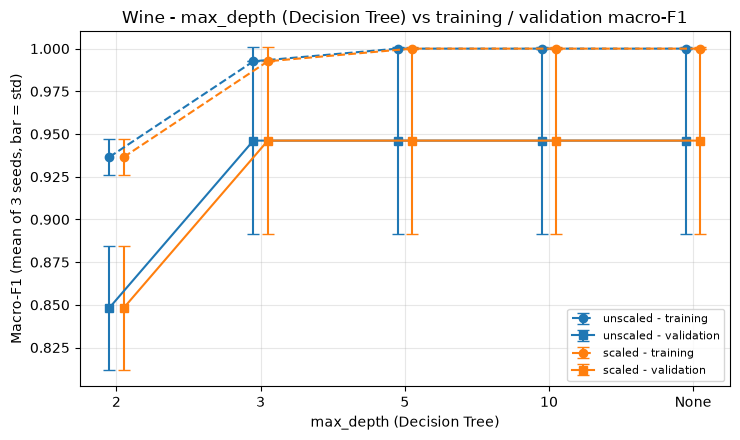

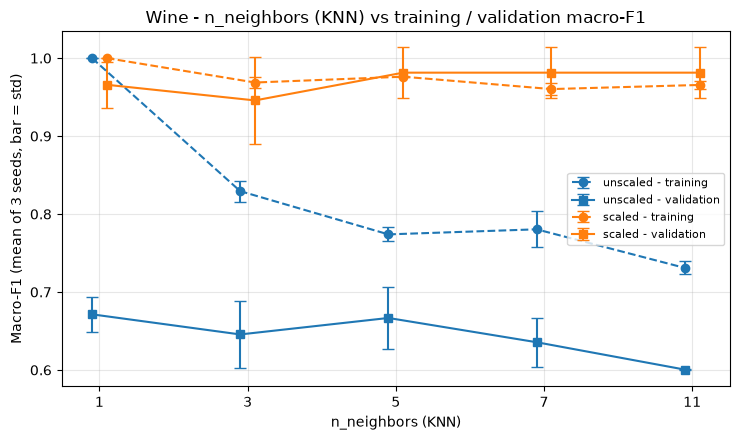

In [29]:
# figure: mean train and validation macro-F1 for every parameter value, both representations, error bar = std of 3 seeds
def plot_param(algo, labels, xlabel, filename):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    x = np.arange(len(labels))
    for rep, color, shift in [("unscaled", "tab:blue", -0.05), ("scaled", "tab:orange", 0.05)]:
        part = summary[(summary["algorithm"] == algo) & (summary["representation"] == rep)]
        ax.errorbar(x + shift, part["train_macro_f1_mean"], yerr=part["train_macro_f1_std"], color=color,
                    linestyle="--", marker="o", capsize=4, label=f"{rep} - training")
        ax.errorbar(x + shift, part["val_macro_f1_mean"], yerr=part["val_macro_f1_std"], color=color,
                    linestyle="-", marker="s", capsize=4, label=f"{rep} - validation")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Macro-F1 (mean of 3 seeds, bar = std)")
    ax.set_title(f"Wine - {xlabel} vs training / validation macro-F1")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

plot_param("dt", ["2", "3", "5", "10", "None"], "max_depth (Decision Tree)", "figures/wine_tree_depth.png")
plot_param("knn", ["1", "3", "5", "7", "11"], "n_neighbors (KNN)", "figures/wine_knn_neighbours.png")

**Interpretation (Section 8):** selected = **wine_knn_scaled_k11**, val macro-F1 = 0.9814 ± 0.0323. KNN k = 5, 7 and 11 (scaled) were exactly the same (same predictions), so the last rule (alphabetical id) picked k11, because as text "k11" comes before "k5".
- **Scaling:** KNN changed the most (k = 11: 0.601 → 0.981), because without scaling proline controls the distance. Decision Tree and GaussianNB are the same on both.
- **Depth:** depth 2 is too simple (0.848), from depth 3 validation stays 0.946 while train goes to 1.000 → overfitting after depth 3.
- **k:** scaled, k = 1 gives 0.966, k = 3 drops to 0.946, k = 5–11 give 0.981, so larger k did not always help.
- **Seeds:** std up to 0.056, validation has only 18 wines (1 wine = 5.6 %). The selected setting got 1.000 on seeds 42 and 52 but 0.944 on seed 62. std is not a confidence interval.

In [30]:
# 9. Evaluating the Selected Model on the Test Set
# 9.1 Final performance metrics
# final test: ONLY the seed 42 model of the selected setting, on the fixed test set, no new training
final_model = models_42[best_id]
X_test_used = X_test_scaled if best["representation"] == "scaled" else X_test   # same preprocessing as the model (seed 42)
test_pred = final_model.predict(X_test_used)
test_proba = final_model.predict_proba(X_test_used)

final_test = pd.DataFrame([{
    "dataset": "wine",
    "selected_configuration": best_id,
    "evaluation_seed": 42,
    "mean_val_macro_f1": best["val_macro_f1_mean"],
    "std_val_macro_f1": best["val_macro_f1_std"],
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_macro_precision": precision_score(y_test, test_pred, average="macro", zero_division=0),
    "test_macro_recall": recall_score(y_test, test_pred, average="macro", zero_division=0),
    "test_macro_f1": f1_score(y_test, test_pred, average="macro", zero_division=0),
    "test_roc_auc": roc_auc_score(y_test, test_proba, multi_class="ovr", average="macro", labels=LABELS),   # same rule as validation
}])
display(final_test.round(4))

,dataset,selected_configuration,evaluation_seed,mean_val_macro_f1,std_val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0


In [31]:
# per-class report: precision, recall, F1 and support for class_0, class_1, class_2
from sklearn.metrics import classification_report
print(classification_report(y_test, test_pred, labels=LABELS, target_names=data.target_names, digits=4, zero_division=0))

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



**Validation vs test:** all 36 test wines are correct, every test score is 1.0000. This is higher than the validation mean (0.9814 ± 0.0323) but inside the seed variation. The model was not changed after the test.

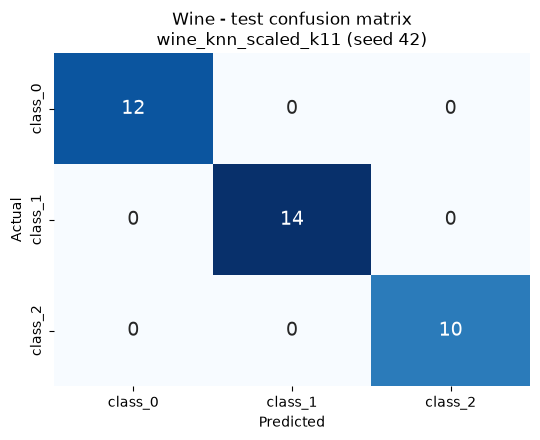

All off-diagonal cells are 0: no test errors, so there is no confusion to explain.


In [32]:
### 9.2 Confusion matrix
# rows = actual, columns = predicted, order [0, 1, 2]
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, test_pred, labels=LABELS)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=data.target_names, yticklabels=data.target_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Wine - test confusion matrix\n{best_id} (seed 42)")
plt.tight_layout()
plt.savefig("figures/wine_confusion_matrix.png", dpi=150)
plt.show()

# biggest number outside the diagonal = most common mistake
largest = (0, None, None)
for i in LABELS:
    for j in LABELS:
        if i != j and cm[i, j] > largest[0]:
            largest = (cm[i, j], i, j)
if largest[0] == 0:
    print("All off-diagonal cells are 0: no test errors, so there is no confusion to explain.")
else:
    print(f"Largest confusion: {largest[0]} wines of class {largest[1]} predicted as class {largest[2]}")

In [33]:
# manual check for ONE class (class 1) against the other two classes
k = 1
TP = cm[k, k]                 # actual class 1, predicted class 1
FP = cm[:, k].sum() - TP      # predicted class 1 but actually another class
FN = cm[k, :].sum() - TP      # actually class 1 but predicted another class
TN = cm.sum() - TP - FP - FN  # everything else
print(f"class {k}: TP = {TP}, FP = {FP}, FN = {FN}, TN = {TN}")

precision_k = TP / (TP + FP) if (TP + FP) > 0 else None   # None = undefined (zero denominator)
recall_k = TP / (TP + FN) if (TP + FN) > 0 else None
f1_k = 2 * precision_k * recall_k / (precision_k + recall_k)
print(f"Manual class {k} precision = {TP}/({TP}+{FP}) = {precision_k:.4f}")
print(f"Manual class {k} recall    = {TP}/({TP}+{FN}) = {recall_k:.4f}")
print(f"Manual class {k} F1        = {f1_k:.4f}")

class 1: TP = 14, FP = 0, FN = 0, TN = 22
Manual class 1 precision = 14/(14+0) = 1.0000
Manual class 1 recall    = 14/(14+0) = 1.0000
Manual class 1 F1        = 1.0000


**Confusion matrix:** only the diagonal has numbers (12, 14, 10), all other cells are 0, so there is no confusion to explain. Manual check for class_1 vs the rest: TP = 14, FP = 0, FN = 0, TN = 22, precision = 14/14 = 1.0000, recall = 14/14 = 1.0000, F1 = 1.0000, same as the class_1 row of the report. No zero denominator.

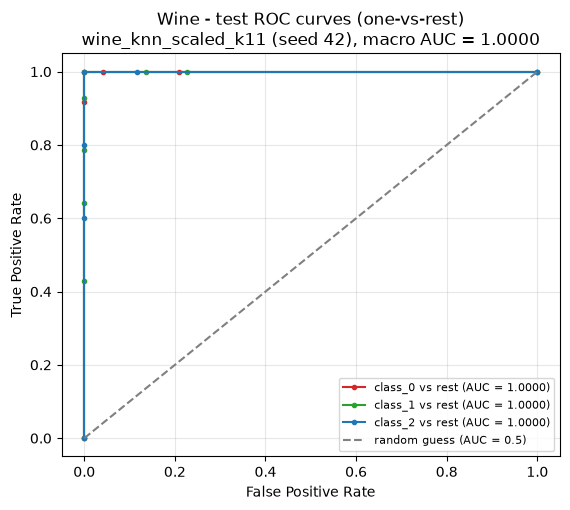

Macro one-vs-rest AUC: 1.0


In [34]:
### 9.3 ROC curve
# one-vs-rest: one curve for every class (this class = positive, other two = negative)
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.8, 5.2))
for c, color in zip(LABELS, ["tab:red", "tab:green", "tab:blue"]):
    fpr, tpr, _ = roc_curve(y_test == c, test_proba[:, c])
    auc_c = roc_auc_score(y_test == c, test_proba[:, c])
    ax.plot(fpr, tpr, marker=".", color=color, label=f"{data.target_names[c]} vs rest (AUC = {auc_c:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="random guess (AUC = 0.5)")
macro_auc = roc_auc_score(y_test, test_proba, multi_class="ovr", average="macro", labels=LABELS)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"Wine - test ROC curves (one-vs-rest)\n{best_id} (seed 42), macro AUC = {macro_auc:.4f}")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/wine_roc_curves.png", dpi=150)
plt.show()
print("Macro one-vs-rest AUC:", round(macro_auc, 4))

**Threshold:** every curve uses the probability of one class. Lower threshold for a class → more wines go to that class → less FN but more FP. Higher threshold → the opposite. Here all three AUC values are 1.0 (macro AUC = 1.0), so the ranking is perfect. No threshold was picked with the test set.

In [35]:
### 9.4 Error interpretation
# which test wines were predicted wrong?
wrong = test_pred != y_test.values
print("Number of test errors:", wrong.sum())
if wrong.sum() > 0:
    display(pd.DataFrame({"row_index": X_test.index[wrong], "actual": y_test.values[wrong],
                          "predicted": test_pred[wrong]}))

# even with no errors some guesses can be close: smallest winning probability on the test set
top_prob = test_proba.max(axis=1)
i = top_prob.argmin()
print(f"Least confident test prediction: row {X_test.index[i]}, actual class {y_test.values[i]}, "
      f"probabilities {test_proba[i].round(3)}")

Number of test errors: 0
Least confident test prediction: row 66, actual class 1, probabilities [0.455 0.545 0.   ]


**Errors:** the model made no test errors. But one error-free test is not proof that the model is perfect: only 36 test wines (1 mistake = 2.8 %), one seed and one split. Wine 66 was close (0.545 for class_1 vs 0.455 for class_0, 6 of 11 neighbours vs 5), and validation seed 62 had an error.

**Limitations:** validation sets are very small (18), the 3 splits overlap, and only one seed (42) and one test set were used.

In [36]:
# 10. K-Means Clustering
#10.1 Fit the clustering model
# 2 representations x 3 seeds = 6 K-Means fits, fitted on train features only, y is NOT given
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

def safe_silhouette(X_part, labels):
    # silhouette needs at least 2 clusters and fewer clusters than samples, otherwise N/A
    if 2 <= len(set(labels)) < len(labels):
        return silhouette_score(X_part, labels)
    return np.nan

km_rows = []
km_models_42 = {}
for seed in SEEDS:
    y_val = splits[seed]["y_val"]
    for rep in ["unscaled", "scaled"]:
        X_train_r, X_val_r = reps[seed][rep]
        km = KMeans(n_clusters=3, random_state=seed, n_init=10)
        km.fit(X_train_r)                          # no labels here
        val_clusters = km.predict(X_val_r)
        km_rows.append({"run_id": f"wine_kmeans_{rep}_k3_s{seed}", "dataset": "wine",
                        "seed": seed, "representation": rep, "n_clusters": 3,
                        "train_inertia": km.inertia_,
                        "val_ari": adjusted_rand_score(y_val, val_clusters),   # labels only used to evaluate
                        "val_silhouette": safe_silhouette(X_val_r, val_clusters)})
        if seed == 42:
            km_models_42[rep] = km

km_runs = pd.DataFrame(km_rows)
display(km_runs.round(4))

,run_id,dataset,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette
0,wine_kmeans_unscaled_k3_s42,wine,42,unscaled,3,1.350496e+06,0.2828,0.4870
1,wine_kmeans_scaled_k3_s42,wine,42,scaled,3,8.747391e+02,1.0000,0.2516
2,wine_kmeans_unscaled_k3_s52,wine,52,unscaled,3,1.303675e+06,0.4006,0.5559
3,wine_kmeans_scaled_k3_s52,wine,52,scaled,3,8.904355e+02,1.0000,0.3010
4,wine_kmeans_unscaled_k3_s62,wine,62,unscaled,3,1.390754e+06,0.4006,0.6867
5,wine_kmeans_scaled_k3_s62,wine,62,scaled,3,8.722466e+02,1.0000,0.2726


In [37]:
# one row per representation: mean and std over seeds, N/A values are skipped (not set to 0) and counted
km_summary = km_runs.groupby("representation", sort=False).agg(
    n_runs=("seed", "count"),
    train_inertia_mean=("train_inertia", "mean"), train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"), val_ari_std=("val_ari", "std"), val_ari_valid_seeds=("val_ari", "count"),
    val_silhouette_mean=("val_silhouette", "mean"), val_silhouette_std=("val_silhouette", "std"),
    val_silhouette_valid_seeds=("val_silhouette", "count")).reset_index()
km_summary.insert(0, "dataset", "wine")
display(km_summary.round(4))

,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_ari_valid_seeds,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_seeds
0,wine,unscaled,3,1.348308e+06,43580.9098,0.3613,0.068,3,0.5765,0.1014,3
1,wine,scaled,3,8.791404e+02,9.8609,1.0000,0.000,3,0.2751,0.0248,3


Raw inertia is not compared between unscaled and scaled, because the two feature spaces have different units.

# 10.2 Final cluster evaluation on the test set

In [38]:
# seed 42 K-Means models predict the test set (no new fit), both representations
km_test_rows = []
for rep, X_t in [("unscaled", X_test), ("scaled", X_test_scaled)]:
    test_clusters = km_models_42[rep].predict(X_t)
    km_test_rows.append({"dataset": "wine", "representation": rep, "seed": 42,
                         "test_cluster_counts": str(pd.Series(test_clusters).value_counts().sort_index().to_dict()),
                         "test_ari": adjusted_rand_score(y_test, test_clusters),
                         "test_silhouette": safe_silhouette(X_t, test_clusters)})
    print(f"Contingency table - {rep} (rows = true class, columns = cluster ID)")
    display(pd.crosstab(y_test.map({0: "0: class_0", 1: "1: class_1", 2: "2: class_2"}), test_clusters,
                        rownames=["true class"], colnames=["cluster"]))

km_test = pd.DataFrame(km_test_rows)
display(km_test.round(4))

Contingency table - unscaled (rows = true class, columns = cluster ID)


cluster,0,1,2
true class,,,
0: class_0,2,10,0
1: class_1,5,0,9
2: class_2,7,0,3


Contingency table - scaled (rows = true class, columns = cluster ID)


cluster,0,1,2
true class,,,
0: class_0,12,0,0
1: class_1,1,13,0
2: class_2,0,0,10


,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,"{0: 14, 1: 10, 2: 12}",0.3733,0.4929
1,wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.9088,0.2711


In [39]:
# 10.3 Visualise and interpret the clusters 
# choose 2 original features using seed 42 TRAIN data: highest ANOVA F (classes far apart),
# second one must not be strongly correlated with the first (|r| < 0.7)
from sklearn.feature_selection import f_classif
train42 = splits[42]["X_train"]
F, _ = f_classif(train42, splits[42]["y_train"])
rank = pd.Series(F, index=train42.columns).sort_values(ascending=False)
feat1 = rank.index[0]
r_with_first = train42.corr()[feat1].abs()
feat2 = [f for f in rank.index[1:] if r_with_first[f] < 0.7][0]
print("Chosen features:", feat1, "and", feat2)

Chosen features: flavanoids and proline


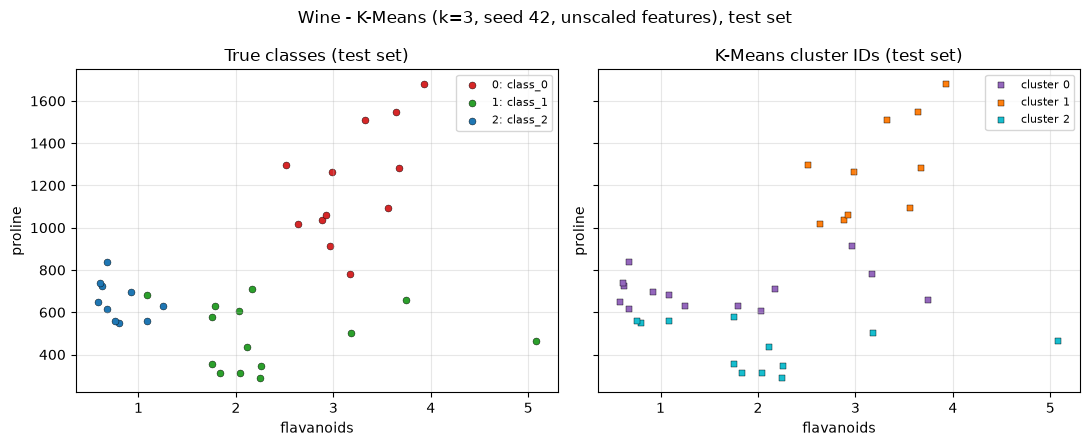

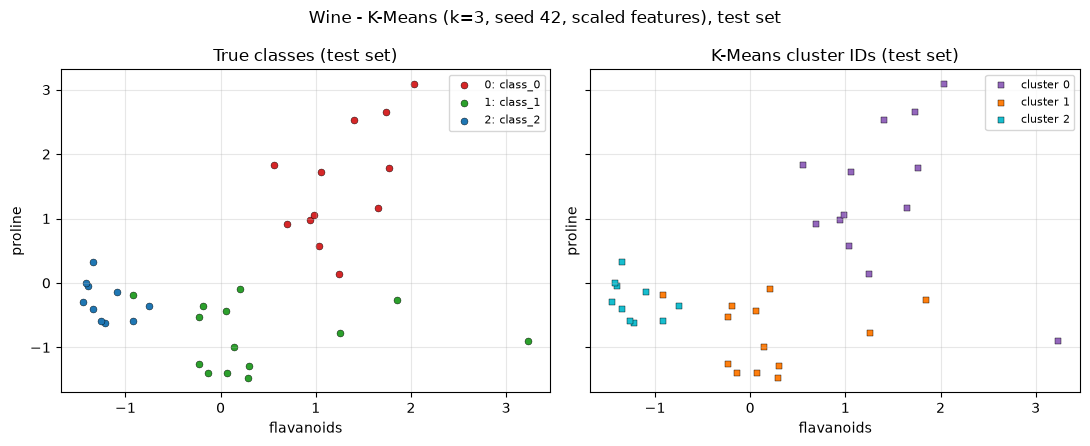

In [40]:
# left: true classes, right: K-Means cluster IDs, same 2 features, test set
def plot_clusters(X_t, clusters, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for c, color in zip(LABELS, ["tab:red", "tab:green", "tab:blue"]):
        m = (y_test == c).values
        axes[0].scatter(X_t.loc[m, feat1], X_t.loc[m, feat2], color=color, s=25, edgecolor="k", linewidth=0.3, label=f"{c}: {data.target_names[c]}")
    for k, color in zip(range(3), ["tab:purple", "tab:orange", "tab:cyan"]):
        m = clusters == k
        axes[1].scatter(X_t.loc[m, feat1], X_t.loc[m, feat2], color=color, s=25, marker="s", edgecolor="k", linewidth=0.3, label=f"cluster {k}")
    axes[0].set_title("True classes (test set)")
    axes[1].set_title("K-Means cluster IDs (test set)")
    for ax in axes:
        ax.set_xlabel(feat1)
        ax.set_ylabel(feat2)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

for rep, X_t in [("unscaled", X_test), ("scaled", X_test_scaled)]:
    clusters = km_models_42[rep].predict(X_t)
    plot_clusters(X_t, clusters, f"Wine - K-Means (k=3, seed 42, {rep} features), test set",
                  f"figures/wine_kmeans_{rep}.png")

**Interpretation (Section 10):** K-Means only saw the train features, the classifiers also saw the labels. Cluster IDs are only names, not classes. Test ARI: unscaled 0.373, scaled 0.909 (validation 0.361 vs 1.000). Unscaled: only cluster 1 is pure (10 class_0), the others mix classes, because proline controls the distance. Scaled: almost one-to-one, only 1 wine is mixed. Silhouette is higher unscaled (0.493 vs 0.271) only because proline dominates that space, so it can not be compared across spaces (same for inertia). The plots use only 2 features (flavanoids, proline), K-Means used all 13.

## Exporting the results (Section 12)
Each notebook writes only its own rows into the shared CSV files; the rows of the other dataset are kept.

In [41]:
# save tables; keep the other dataset's rows if the file already exists
os.makedirs("results", exist_ok=True)

def save_csv(df, name, dataset="wine"):
    path = f"results/{name}"
    if os.path.exists(path):
        old = pd.read_csv(path)
        df = pd.concat([old[old["dataset"] != dataset], df], ignore_index=True)
    df = df.sort_values("dataset", kind="stable")
    df.to_csv(path, index=False)
    print(f"{name:25s} -> {len(df)} rows ({(df['dataset'] == dataset).sum()} from {dataset})")

save_csv(runs, "classifier_runs.csv")
save_csv(summary, "classifier_summary.csv")
save_csv(final_test, "classifier_test.csv")
save_csv(km_runs, "kmeans_runs.csv")
save_csv(km_summary, "kmeans_summary.csv")
save_csv(km_test, "kmeans_test.csv")
print("Figures:", sorted(f for f in os.listdir("figures") if f.startswith("wine_")))

classifier_runs.csv       -> 132 rows (66 from wine)
classifier_summary.csv    -> 44 rows (22 from wine)
classifier_test.csv       -> 2 rows (1 from wine)
kmeans_runs.csv           -> 12 rows (6 from wine)
kmeans_summary.csv        -> 4 rows (2 from wine)
kmeans_test.csv           -> 4 rows (2 from wine)
Figures: ['wine_boxplots.png', 'wine_class_distribution.png', 'wine_confusion_matrix.png', 'wine_correlation_heatmap.png', 'wine_kmeans_scaled.png', 'wine_kmeans_unscaled.png', 'wine_knn_neighbours.png', 'wine_roc_curves.png', 'wine_tree_depth.png']
